In [1]:
import mygene
import pyreadr
import numpy as np
from scipy.sparse.csgraph import connected_components
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

In [2]:
adata = sc.read('/home/csb/Saloni/SCENT/data/preprocessed_adata.h5ad')

print(adata)

AnnData object with n_obs × n_vars = 16822 × 5000
    obs: 'sample', 'clusters', 'prior_time', 'librarysize'
    var: 'gene_ids', 'feature_types', 'genome', 'means', 'dispersions', 'dispersions_norm'
    uns: 'clusters_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap', 'X_umap_rna_unintegrated'
    varm: 'PCs'
    layers: 'raw', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'


In [ ]:
from pathlib import Path
import pyreadr
import numpy as np

PROJECT_ROOT = Path("..").resolve()

PPI_FILE = PROJECT_ROOT / "src" / "scent" / "data" / "net13Jun12.rda"

result = pyreadr.read_r(str(PPI_FILE))

print(result.keys())

net_df = result["net13Jun12.m"]

net_gene_ids = net_df.index.astype(str).tolist()
A_full = net_df.values.astype(np.float32)

print(A_full.shape)

assert np.allclose(A_full, A_full.T)
assert np.all(np.diag(A_full) == 0)

PyreadrError: File b'/home/csb/Saloni/EMT_ID/EMT_ID/SCENT/data/net13Jun12.rda' does not exist!

In [4]:
import mygene

mg = mygene.MyGeneInfo()

# Query as MOUSE genes, ask for the human ortholog via homologene
query = mg.querymany(
    adata.var_names.tolist(),
    scopes='symbol,alias',
    fields='entrezgene,homologene',
    species='mouse',
    returnall=True
)

symbol_to_entrez = {}

for q in query['out']:
    if 'homologene' in q and 'genes' in q['homologene']:
        for taxid, entrez in q['homologene']['genes']:
            if taxid == 9606:  # human
                symbol_to_entrez[q['query']] = str(entrez)
                break

print(f"Mapped: {len(symbol_to_entrez)} / {adata.n_vars}")

399 input query terms found dup hits:	[('Gm41541', 2), ('Gm40773', 2), ('Gm14966', 2), ('Ankrd12', 2), ('Hnf1aos1', 2), ('H4c8', 10), ('Gb
24 input query terms found no hit:	['Gm47771', 'BC051142', 'BC052040', 'Gm49390', 'Gm10974', 'Gm11099', 'Gm45323', 'Gm49317', 'Gm11146'


Mapped: 4176 / 5000


In [5]:
common_symbols = [s for s in symbol_to_entrez if symbol_to_entrez[s] in net_gene_ids]
common_entrez = [symbol_to_entrez[s] for s in common_symbols]

entrez_idx = [net_gene_ids.index(e) for e in common_entrez]
A_sub = A_full[np.ix_(entrez_idx, entrez_idx)]

n_comp, labels = connected_components(A_sub, directed=False)
largest = np.bincount(labels).argmax()
mask = labels == largest

A_final = A_sub[mask][:, mask]
final_symbols = [s for s, m in zip(common_symbols, mask) if m]

print(f"Final network-aligned gene set: {len(final_symbols)} genes")
# Sanity check target: SCENT/CCAT papers typically retain 8,000-12,000 genes.
# If you're far below that, something's off upstream — worth a look before continuing.

Final network-aligned gene set: 2501 genes


In [6]:
adata_sub = adata[:, final_symbols].copy()
X_raw = adata_sub.X.toarray() if hasattr(adata_sub.X, 'toarray') else adata_sub.X

X_log = np.log(X_raw + 1.1).astype(np.float32)

In [7]:
def compute_CCAT_vectorized(X, A):
    """X: (n_cells, n_genes) log-normalized expression.
       A: (n_genes, n_genes) adjacency matrix, same gene order as X's columns."""
    k = A.sum(axis=1)                        # node degree, (n_genes,)
    k_c = k - k.mean()
    X_c = X - X.mean(axis=1, keepdims=True)

    cov = X_c @ k_c
    std_x = np.sqrt((X_c ** 2).sum(axis=1))
    std_k = np.sqrt((k_c ** 2).sum())

    return cov / (std_x * std_k)

adata.obs['CCAT'] = compute_CCAT_vectorized(X_log, A_final)
print(adata.obs['CCAT'].describe())

count    16822.000000
mean         0.196564
std          0.062764
min          0.045916
25%          0.149248
50%          0.179896
75%          0.234138
max          0.382753
Name: CCAT, dtype: float64


In [8]:
adata.obs.groupby("clusters")["CCAT"].describe()

/tmp/ipykernel_820936/3874991944.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("clusters")["CCAT"].describe()


,count,mean,std,min,25%,50%,75%,max
clusters,,,,,,,,
Alpha,1159.0,0.147100,0.025444,0.068731,0.129599,0.148764,0.164753,0.236230
Beta,936.0,0.140254,0.023737,0.046312,0.125713,0.140729,0.155685,0.222910
Delta,239.0,0.131307,0.024593,0.045916,0.114912,0.132425,0.145466,0.203297
Ductal,3717.0,0.239861,0.036570,0.098697,0.215037,0.238753,0.263634,0.355864
Epsilon,290.0,0.154712,0.023984,0.089388,0.139817,0.152986,0.169795,0.238010
Fev+,1298.0,0.148489,0.021179,0.079770,0.134136,0.149355,0.162951,0.209137
Fev+ Alpha,333.0,0.147486,0.022017,0.087466,0.132423,0.146463,0.162757,0.210312
Fev+ Beta,1439.0,0.148942,0.021966,0.070080,0.133967,0.149634,0.163718,0.219569
Fev+ Delta,296.0,0.155401,0.023393,0.093178,0.140433,0.154192,0.169402,0.245201


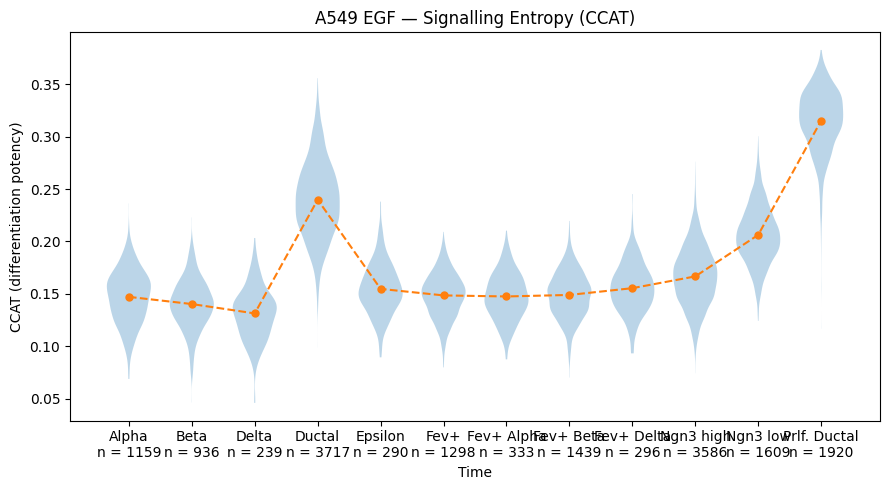

In [9]:
cluster = ["Alpha", "Beta", "Delta", "Ductal", "Epsilon", "Fev+", "Fev+ Alpha", "Fev+ Beta", "Fev+ Delta", "Ngn3 high", "Ngn3 low", "Prlf. Ductal"]

positions = {
    "Ngn3 low": 0,
    "Ngn3 high": 1,
    "Fev+": 2,
    "Fev+ Alpha": 3,
    "Fev+ Beta": 4,
    "Fev+ Delta": 5,
    "Alpha": 3,
    "Beta": 4,
    "Delta": 5,
}

# ------------------------------------------------------------
# CCAT values for each dose
# ------------------------------------------------------------

ccat_groups = [
    adata.obs.loc[
        adata.obs["clusters"] == dose,
        "CCAT"
    ].dropna().values
    for dose in cluster
]

# Mean CCAT at each dose
ccat_means = [
    np.mean(group)
    for group in ccat_groups
]

# Number of cells
cell_counts = (
    adata.obs["clusters"]
    .value_counts()
    .reindex(cluster)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(cluster))

# Simple violin
ax.violinplot(
    ccat_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Mean trajectory
ax.plot(
    positions,
    ccat_means,
    "o--",
    linewidth=1.5,
    markersize=5
)

# X-axis labels
labels = [
    f"{time}\nn = {int(cell_counts.loc[time])}"
    for time in cluster
]

ax.set_xticks(positions)
ax.set_xticklabels(labels)

ax.set_xlabel("Time")
ax.set_ylabel("CCAT (differentiation potency)")

ax.set_title("A549 EGF — Signalling Entropy (CCAT)")

plt.tight_layout()
plt.show()

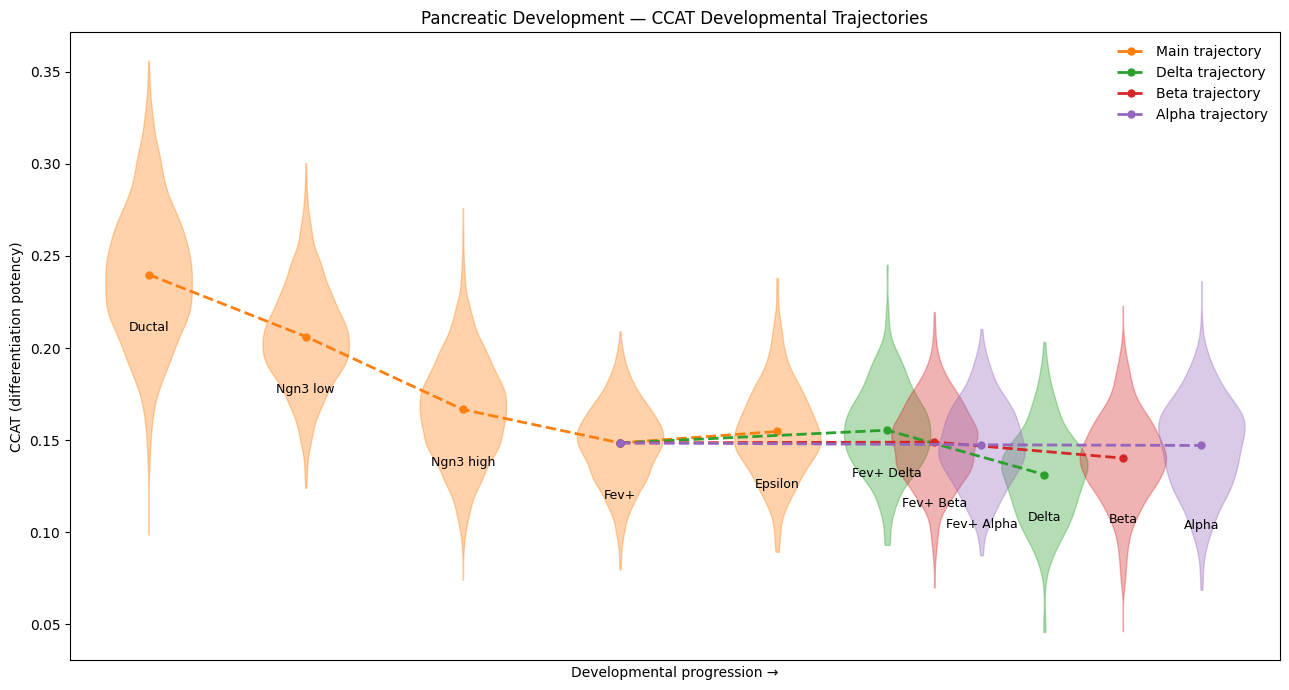

In [10]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# ORDER — only for looking up the data
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon",
    "Fev+ Delta",
    "Delta",
    "Fev+ Beta",
    "Beta",
    "Fev+ Alpha",
    "Alpha"
]

# ============================================================
# TRAJECTORY COLORS
# ============================================================

colors = {
    "main":   "tab:orange",
    "delta":  "tab:green",
    "beta":   "tab:red",
    "alpha":  "tab:purple"
}


# ============================================================
# ASSIGN EACH CLUSTER TO A TRAJECTORY
# ============================================================

trajectory = {

    # Main trajectory
    "Ductal":       "main",
    "Ngn3 low":     "main",
    "Ngn3 high":    "main",
    "Fev+":         "main",
    "Epsilon":      "main",

    # Delta branch
    "Fev+ Delta":   "delta",
    "Delta":        "delta",

    # Beta branch
    "Fev+ Beta":    "beta",
    "Beta":         "beta",

    # Alpha branch
    "Fev+ Alpha":   "alpha",
    "Alpha":        "alpha",
}


# ============================================================
# GET CCAT DISTRIBUTIONS
# ============================================================

ccat_groups = {
    name: adata.obs.loc[
        adata.obs["clusters"] == name,
        "CCAT"
    ].dropna().values
    for name in cluster
}

ccat_means = {
    name: np.mean(values)
    for name, values in ccat_groups.items()
}

cell_counts = {
    name: len(values)
    for name, values in ccat_groups.items()
}


# ============================================================
# DEVELOPMENTAL LAYOUT
#
# IMPORTANT:
# x positions are ONLY for displaying the developmental tree.
# y positions are the actual CCAT values.
# ============================================================

x = {
    # Main trajectory
    "Ductal":       0.0,
    "Ngn3 low":     1.0,
    "Ngn3 high":    2.0,
    "Fev+":         3.0,
    "Epsilon":      4.0,

    # Delta branch
    "Fev+ Delta":   4.7,
    "Delta":        5.7,

    # Beta branch
    "Fev+ Beta":    5.0,
    "Beta":         6.2,

    # Alpha branch
    "Fev+ Alpha":   5.3,
    "Alpha":        6.7,
}


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# VIOLINS
# ============================================================

for name in cluster:

    values = ccat_groups[name]

    if len(values) == 0:
        continue

    color = colors[trajectory[name]]

    vp = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.55,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Color violin according to trajectory
    for body in vp["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.35)



# ============================================================
# TRAJECTORIES
# ============================================================

# Main trajectory
main_path = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon"
]

ax.plot(
    [x[name] for name in main_path],
    [ccat_means[name] for name in main_path],
    "o--",
    color=colors["main"],
    linewidth=2,
    markersize=5,
    label="Main trajectory"
)


# Delta
delta_path = [
    "Fev+",
    "Fev+ Delta",
    "Delta"
]

ax.plot(
    [x[name] for name in delta_path],
    [ccat_means[name] for name in delta_path],
    "o--",
    color=colors["delta"],
    linewidth=2,
    markersize=5,
    label="Delta trajectory"
)


# Beta
beta_path = [
    "Fev+",
    "Fev+ Beta",
    "Beta"
]

ax.plot(
    [x[name] for name in beta_path],
    [ccat_means[name] for name in beta_path],
    "o--",
    color=colors["beta"],
    linewidth=2,
    markersize=5,
    label="Beta trajectory"
)


# Alpha
alpha_path = [
    "Fev+",
    "Fev+ Alpha",
    "Alpha"
]

ax.plot(
    [x[name] for name in alpha_path],
    [ccat_means[name] for name in alpha_path],
    "o--",
    color=colors["alpha"],
    linewidth=2,
    markersize=5,
    label="Alpha trajectory"
)


# ============================================================
# LABELS
# ============================================================

# Different vertical offsets prevent labels from sitting directly
# on top of one another when their CCAT values are similar.

label_offset = {
    "Ductal":       -0.025,
    "Ngn3 low":     -0.025,
    "Ngn3 high":    -0.025,
    "Fev+":         -0.025,
    "Epsilon":      -0.025,

    "Fev+ Delta":   -0.020,
    "Delta":        -0.020,

    "Fev+ Beta":    -0.030,
    "Beta":         -0.030,

    "Fev+ Alpha":   -0.040,
    "Alpha":        -0.040,
}


for name in cluster:

    if len(ccat_groups[name]) == 0:
        continue

    ax.text(
        x[name],
        ccat_means[name] + label_offset[name],
        f"{name}",
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 7.2)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("CCAT (differentiation potency)")

ax.set_title(
    "Pancreatic Development — CCAT Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

Terminal endocrine group:
Epsilon + Delta + Beta + Alpha
n = 2624

FIRST 2 / 3 / 4 vs LAST 4


,Comparison,t_stat,p_value,n_early,n_terminal,p_adj
0,First 2,120.284363,0.0,5326,2624,0.0
1,First 3,86.885017,0.0,8912,2624,0.0
2,First 4,78.031708,0.0,10210,2624,0.0


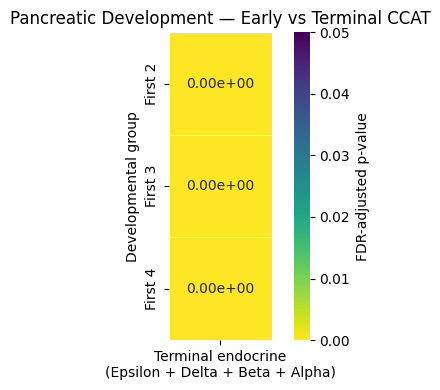


INDIVIDUAL EARLY GROUPS vs LAST 4


,Comparison,t_stat,p_value,n_early,n_terminal,p_adj
0,Ductal,123.238917,0.000000e+00,3717,2624,0.000000e+00
1,Ngn3 low,73.780242,0.000000e+00,1609,2624,0.000000e+00
2,Ngn3 high,33.133681,4.529565e-221,3586,2624,6.039420e-221
3,Fev+,5.765142,8.979512e-09,1298,2624,8.979512e-09


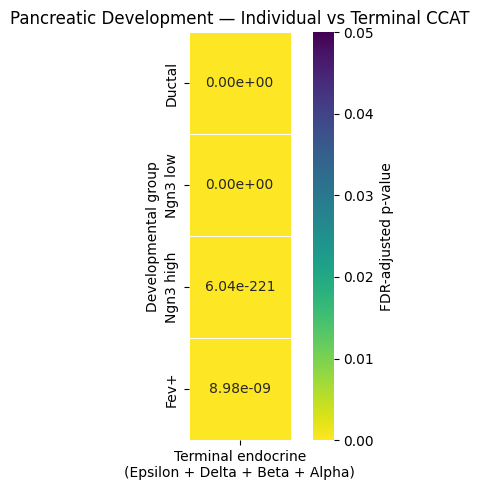

In [11]:
# ============================================================
# PANCREATIC DEVELOPMENT — CCAT GROUP-WISE STATISTICS
#
# Heatmap 1:
#   First 2 vs last 4
#   First 3 vs last 4
#   First 4 vs last 4
#
# Heatmap 2:
#   Ductal vs last 4
#   Ngn3 low vs last 4
#   Ngn3 high vs last 4
#   Fev+ vs last 4
#
# Test:
#   Welch's t-test
#   Benjamini-Hochberg FDR correction
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests


# ============================================================
# DEFINE DEVELOPMENTAL GROUPS
# ============================================================

# Terminal endocrine populations
terminal_groups = [
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha"
]

# Early developmental trajectory
first_4 = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+"
]

first_3 = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high"
]

first_2 = [
    "Ductal",
    "Ngn3 low"
]


# ============================================================
# INDIVIDUAL EARLY GROUPS
# ============================================================

individual_groups = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+"
]


# ============================================================
# GET CCAT VALUES
# ============================================================

ccat_groups = {
    name: adata.obs.loc[
        adata.obs["clusters"] == name,
        "CCAT"
    ].dropna().values
    for name in cluster
}


# ============================================================
# COMBINE TERMINAL GROUP
# ============================================================

terminal_values = np.concatenate([
    ccat_groups[name]
    for name in terminal_groups
    if len(ccat_groups[name]) > 0
])


print("Terminal endocrine group:")
print("Epsilon + Delta + Beta + Alpha")
print(f"n = {len(terminal_values)}")


# ============================================================
# FUNCTION TO CALCULATE WELCH TESTS
# ============================================================

def compare_to_terminal(group_definitions):

    results = []

    for label, groups in group_definitions.items():

        early_values = np.concatenate([
            ccat_groups[name]
            for name in groups
            if len(ccat_groups[name]) > 0
        ])

        statistic, p_value = ttest_ind(
            early_values,
            terminal_values,
            equal_var=False
        )

        results.append({
            "Comparison": label,
            "t_stat": statistic,
            "p_value": p_value,
            "n_early": len(early_values),
            "n_terminal": len(terminal_values)
        })

    results = pd.DataFrame(results)

    # --------------------------------------------------------
    # FDR correction
    # --------------------------------------------------------

    results["p_adj"] = multipletests(
        results["p_value"],
        method="fdr_bh"
    )[1]

    return results


# ============================================================
# HEATMAP 1
# ============================================================

group_comparisons_1 = {

    "First 2": first_2,
    "First 3": first_3,
    "First 4": first_4
}

results_1 = compare_to_terminal(group_comparisons_1)

print("\n========================================")
print("FIRST 2 / 3 / 4 vs LAST 4")
print("========================================")

display(results_1)


# ------------------------------------------------------------
# Create heatmap matrix
# ------------------------------------------------------------

heatmap_1 = pd.DataFrame(
    results_1["p_adj"].values,
    index=results_1["Comparison"],
    columns=["Terminal endocrine\n(Epsilon + Delta + Beta + Alpha)"]
)


plt.figure(figsize=(5, 4))

sns.heatmap(
    heatmap_1,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "FDR-adjusted p-value"
    }
)

plt.title(
    "Pancreatic Development — Early vs Terminal CCAT"
)

plt.xlabel("")
plt.ylabel("Developmental group")

plt.tight_layout()
plt.show()


# ============================================================
# HEATMAP 2
# ============================================================

group_comparisons_2 = {

    "Ductal": ["Ductal"],
    "Ngn3 low": ["Ngn3 low"],
    "Ngn3 high": ["Ngn3 high"],
    "Fev+": ["Fev+"]
}

results_2 = compare_to_terminal(group_comparisons_2)

print("\n========================================")
print("INDIVIDUAL EARLY GROUPS vs LAST 4")
print("========================================")

display(results_2)


# ------------------------------------------------------------
# Create heatmap matrix
# ------------------------------------------------------------

heatmap_2 = pd.DataFrame(
    results_2["p_adj"].values,
    index=results_2["Comparison"],
    columns=["Terminal endocrine\n(Epsilon + Delta + Beta + Alpha)"]
)


plt.figure(figsize=(5, 5))

sns.heatmap(
    heatmap_2,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "FDR-adjusted p-value"
    }
)

plt.title(
    "Pancreatic Development — Individual vs Terminal CCAT"
)

plt.xlabel("")
plt.ylabel("Developmental group")

plt.tight_layout()
plt.show()

Shannon Entropy

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Calculate Shannon entropy per cell
# ------------------------------------------------------------

X = adata.X

if hasattr(X, "toarray"):
    X = X.toarray()

X = np.asarray(X, dtype=np.float64)

# Convert expression to probabilities within each cell
row_sums = X.sum(axis=1)

# Avoid division by zero
valid = row_sums > 0

P = np.zeros_like(X)

P[valid] = X[valid] / row_sums[valid, None]

# Shannon entropy
shannon_entropy = np.zeros(X.shape[0])

shannon_entropy[valid] = -np.sum(
    np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),
    axis=1
)

adata.obs["Shannon_entropy"] = shannon_entropy

print(adata.obs["Shannon_entropy"].describe())

count    16822.000000
mean         6.674371
std          0.207709
min          6.053411
25%          6.527942
50%          6.660483
75%          6.812872
max          7.465054
Name: Shannon_entropy, dtype: float64


/tmp/ipykernel_339580/3058785346.py:30: RuntimeWarning: divide by zero encountered in log
  np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),
/tmp/ipykernel_339580/3058785346.py:30: RuntimeWarning: invalid value encountered in multiply
  np.where(P[valid] > 0, P[valid] * np.log(P[valid]), 0),


/tmp/ipykernel_339580/3624976690.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("clusters")["Shannon_entropy"]


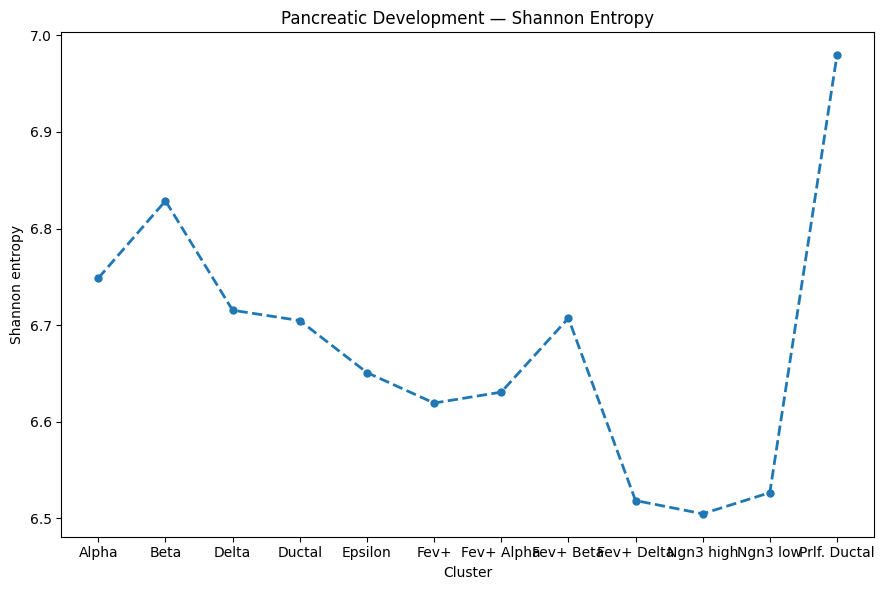

In [23]:
cluster = ["Alpha", "Beta", "Delta", "Ductal", "Epsilon", "Fev+", "Fev+ Alpha", "Fev+ Beta", "Fev+ Delta", "Ngn3 high", "Ngn3 low", "Prlf. Ductal"]

entropy_means = (
    adata.obs
    .groupby("clusters")["Shannon_entropy"]
    .mean()
    .reindex(cluster)
)

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(cluster))

ax.plot(
    x,
    entropy_means.values,
    "o--",
    linewidth=2,
    markersize=5
)

ax.set_xticks(x)

ax.set_xticklabels([
    f"{clust}"
    for clust in cluster
])

ax.set_xlabel("Cluster")
ax.set_ylabel("Shannon entropy")

ax.set_title("Pancreatic Development — Shannon Entropy")

plt.tight_layout()
plt.show()

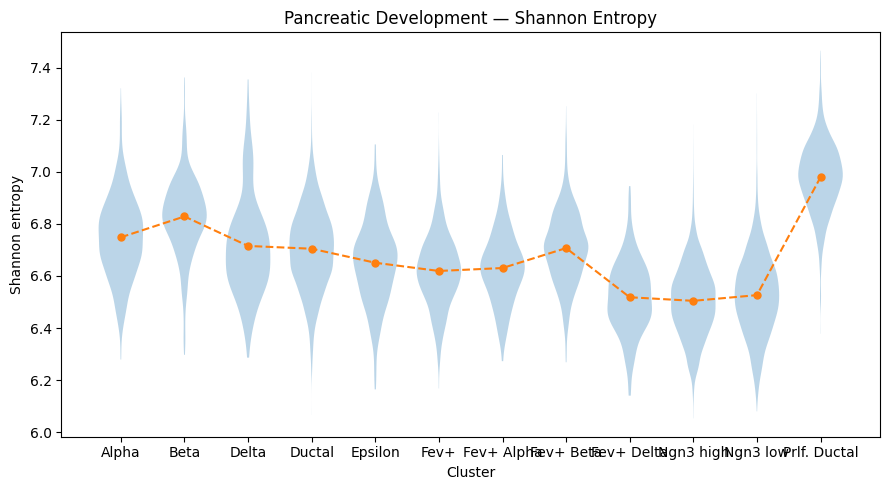

In [24]:
entropy_groups = [
    adata.obs.loc[
        adata.obs["clusters"] == clust,
        "Shannon_entropy"
    ].dropna().values
    for clust in cluster
]

entropy_means = [
    np.mean(group)
    for group in entropy_groups
]

cell_counts = (
    adata.obs["clusters"]
    .value_counts()
    .reindex(cluster)
)

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(cluster))

ax.violinplot(
    entropy_groups,
    positions=positions,
    widths=0.7,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Mean trajectory
ax.plot(
    positions,
    entropy_means,
    "o--",
    linewidth=1.5,
    markersize=5
)

# Dose + n cells
ax.set_xticks(positions)

ax.set_xticklabels([
    f"{clust}"
    for clust in cluster
])

ax.set_xlabel("Cluster")
ax.set_ylabel("Shannon entropy")

ax.set_title("Pancreatic Development — Shannon Entropy")

plt.tight_layout()
plt.show()

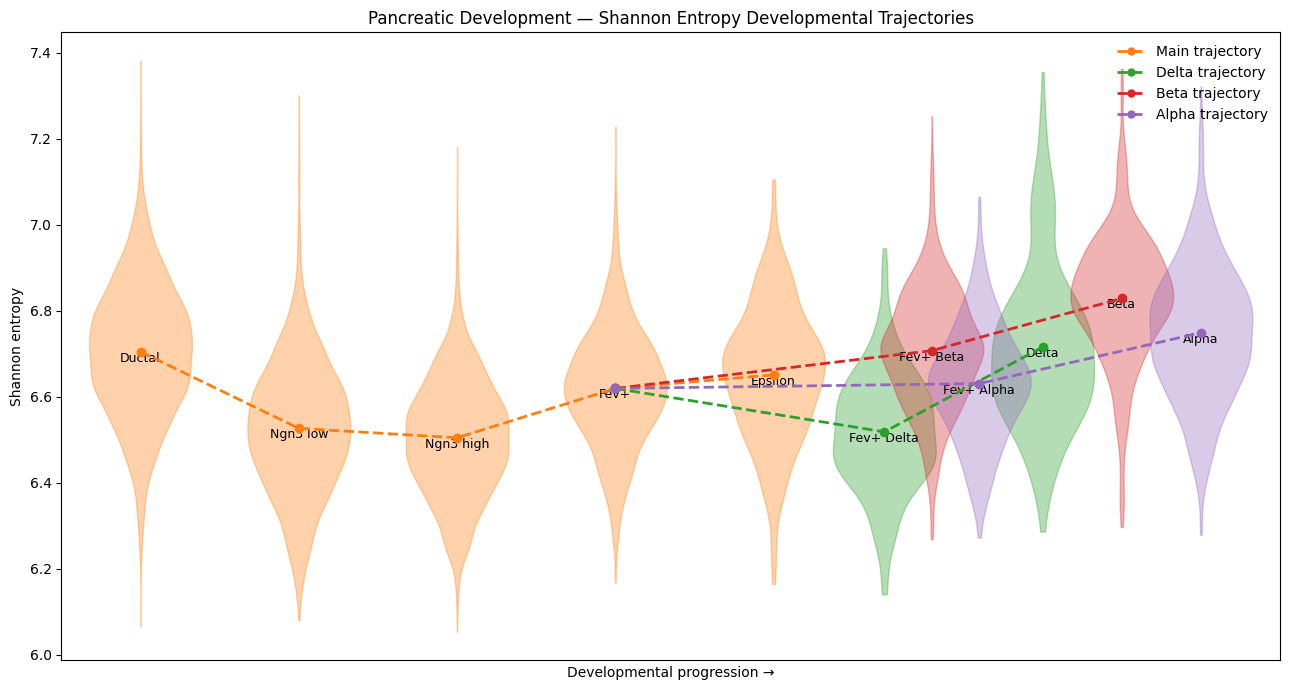

In [26]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DEVELOPMENTAL ORDER
# ============================================================

cluster = [
    "Ductal",
    "Ngn3 low",
    "Ngn3 high",
    "Fev+",
    "Epsilon",
    "Fev+ Delta",
    "Delta",
    "Fev+ Beta",
    "Beta",
    "Fev+ Alpha",
    "Alpha"
]


# ============================================================
# GET SHANNON ENTROPY DISTRIBUTIONS
# ============================================================

entropy_groups = {
    name: adata.obs.loc[
        adata.obs["clusters"] == name,
        "Shannon_entropy"
    ].dropna().values
    for name in cluster
}


# ============================================================
# MEAN SHANNON ENTROPY
# ============================================================

entropy_means = {
    name: np.mean(values)
    for name, values in entropy_groups.items()
}


# ============================================================
# NUMBER OF CELLS
# ============================================================

cell_counts = {
    name: len(entropy_groups[name])
    for name in entropy_groups
}


# ============================================================
# X POSITIONS
# Same developmental layout as ID / CCAT
# ============================================================

x = {

    # Main trajectory
    "Ductal":       0.0,
    "Ngn3 low":     1.0,
    "Ngn3 high":    2.0,
    "Fev+":         3.0,
    "Epsilon":      4.0,

    # Delta branch
    "Fev+ Delta":   4.7,
    "Delta":        5.7,

    # Beta branch
    "Fev+ Beta":    5.0,
    "Beta":         6.2,

    # Alpha branch
    "Fev+ Alpha":   5.3,
    "Alpha":        6.7,
}


# ============================================================
# TRAJECTORY COLORS
# Same colors as ID plot
# ============================================================

colors = {
    "main":  "tab:orange",
    "delta": "tab:green",
    "beta":  "tab:red",
    "alpha": "tab:purple"
}


# ============================================================
# TRAJECTORY ASSIGNMENT
# ============================================================

trajectory = {

    # Main
    "Ductal": "main",
    "Ngn3 low": "main",
    "Ngn3 high": "main",
    "Fev+": "main",
    "Epsilon": "main",

    # Delta
    "Fev+ Delta": "delta",
    "Delta": "delta",

    # Beta
    "Fev+ Beta": "beta",
    "Beta": "beta",

    # Alpha
    "Fev+ Alpha": "alpha",
    "Alpha": "alpha",
}


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(13, 7))


# ============================================================
# DRAW VIOLINS
# ============================================================

for name in cluster:

    if name not in entropy_groups:
        continue

    values = entropy_groups[name]

    if len(values) == 0:
        continue

    color = colors[trajectory[name]]

    vp = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    # Color according to developmental trajectory
    for body in vp["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.35)


# ============================================================
# HELPER FUNCTION
# ============================================================

def plot_entropy_trajectory(ax, path, color, label):

    # --------------------------------------------------------
    # Mean points
    # --------------------------------------------------------

    for name in path:

        if name not in entropy_means:
            continue

        ax.plot(
            x[name],
            entropy_means[name],
            "o",
            color=color,
            markersize=6,
            zorder=5
        )

    # --------------------------------------------------------
    # Connecting trajectory
    # --------------------------------------------------------

    ax.plot(
        [x[name] for name in path],
        [entropy_means[name] for name in path],
        "o--",
        color=color,
        linewidth=2,
        markersize=5,
        label=label,
        zorder=4
    )


# ============================================================
# MAIN TRAJECTORY
#
# Ductal → Ngn3 low → Ngn3 high → Fev+ → Epsilon
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Ductal",
        "Ngn3 low",
        "Ngn3 high",
        "Fev+",
        "Epsilon"
    ],
    colors["main"],
    "Main trajectory"
)


# ============================================================
# DELTA BRANCH
#
# Fev+ → Fev+ Delta → Delta
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Fev+",
        "Fev+ Delta",
        "Delta"
    ],
    colors["delta"],
    "Delta trajectory"
)


# ============================================================
# BETA BRANCH
#
# Fev+ → Fev+ Beta → Beta
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Fev+",
        "Fev+ Beta",
        "Beta"
    ],
    colors["beta"],
    "Beta trajectory"
)


# ============================================================
# ALPHA BRANCH
#
# Fev+ → Fev+ Alpha → Alpha
# ============================================================

plot_entropy_trajectory(
    ax,
    [
        "Fev+",
        "Fev+ Alpha",
        "Alpha"
    ],
    colors["alpha"],
    "Alpha trajectory"
)


# ============================================================
# LABELS
# ============================================================

for name in cluster:

    if name not in entropy_means:
        continue

    ax.text(
        x[name],
        entropy_means[name],
        f"{name}",
        ha="center",
        va="top",
        fontsize=9
    )


# ============================================================
# FORMATTING
# ============================================================

ax.set_xlim(-0.5, 7.2)

ax.set_xticks([])

ax.set_xlabel("Developmental progression →")

ax.set_ylabel("Shannon entropy")

ax.set_title(
    "Pancreatic Development — Shannon Entropy Developmental Trajectories"
)

ax.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()